# EDA - SPEDIA Security Logs

Notebook khảo sát dữ liệu chuẩn hóa trước khi huấn luyện Logistic Regression và Random Forest. Các biểu đồ được tạo trực tiếp từ CSV, không dùng ảnh dựng sẵn. Nhãn `Anomaly` chỉ dùng để phân tích/đánh giá, không làm feature inference.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

search_roots = [Path.cwd(), *Path.cwd().parents]
search_roots.extend(path for path in Path.cwd().iterdir() if path.is_dir())
PROJECT_ROOT = next(
    (path for path in search_roots
     if (path / "preprocessing" / "data_bundle.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy preprocessing/data_bundle.py từ thư mục hiện tại.")

sys.path.insert(0, str(PROJECT_ROOT))
from preprocessing.data_bundle import load_table

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
df = load_table("normalized_logs.csv", base_dir=DATA_DIR)
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

print(f"Số dòng/cột: {df.shape[0]:,} / {df.shape[1]:,}")
print(f"Timestamp hợp lệ: {df['Timestamp'].notna().sum():,}/{len(df):,}")
print(f"Khoảng thời gian: {df['Timestamp'].min()} -> {df['Timestamp'].max()}")

Số dòng/cột: 72,250 / 43
Timestamp hợp lệ: 72,250/72,250
Khoảng thời gian: 2025-03-06 11:46:28 -> 2025-03-30 19:45:22.120000


## 1. Cấu trúc, chất lượng và giá trị thiếu

,dtype,missing,missing_pct,unique
source_row_id,string,0,0.00,72250
record_index,int64,0,0.00,72250
id,string,0,0.00,72250
Timestamp,datetime64[ns],0,0.00,66077
Activity,string,0,0.00,6
Action,string,0,0.00,13
Decoder_name,string,0,0.00,7
User,string,1372,1.90,17
Agent_name,string,0,0.00,83
hour,Int64,0,0.00,24


Dòng trùng hoàn toàn: 0


,source_row_id,record_index,id,Timestamp,Activity,Action,Decoder_name,User,Agent_name,hour,...,Size_raw,Size_before_raw,Size_after_raw,Level_raw,Timestamp_raw,Activity_raw,Action_raw,Decoder_name_raw,User_raw,Agent_name_raw
0,04d26536dd8fc85cb8f97ce3ef491725a19544400e86a6...,1756,ed5ba020-268b-40a9-825f-675589b5b80e,2025-03-06 11:46:28,http,url accedida,cert,camilo,public-host_simulation,11,...,,,,,2025-03-06 11:46:28.000,http,URL accedida,cert,camilo,public-host_simulation
1,04d26536dd8fc85cb8f97ce3ef491725a19544400e86a6...,55,0f2eebd9-d1f2-42c0-9767-7c0398696d4d,2025-03-06 11:46:31,device,disconnect,cert,camilo,public-host_simulation,11,...,,,,,2025-03-06 11:46:31.000,device,Disconnect,cert,camilo,public-host_simulation
2,04d26536dd8fc85cb8f97ce3ef491725a19544400e86a6...,1757,68dce8bd-4e17-4a2a-9846-07e9d8485ef5,2025-03-06 11:46:35,file,file accessed,cert,camilo,public-host_simulation,11,...,,,,,2025-03-06 11:46:35.000,file,File accessed,cert,camilo,public-host_simulation
3,04d26536dd8fc85cb8f97ce3ef491725a19544400e86a6...,54,16d3389e-73e1-49c8-9c1d-5c4bc1bd27f5,2025-03-06 11:47:03,http,url accedida,cert,olaya,internal-server_simulation,11,...,,,,,2025-03-06 11:47:03.000,http,URL accedida,cert,olaya,internal-server_simulation
4,04d26536dd8fc85cb8f97ce3ef491725a19544400e86a6...,53,9ef0a4da-1c1f-43a2-8859-cdf19774ed09,2025-03-06 11:47:06,file,file accessed,cert,olaya,internal-server_simulation,11,...,,,,,2025-03-06 11:47:06.000,file,File accessed,cert,olaya,internal-server_simulation


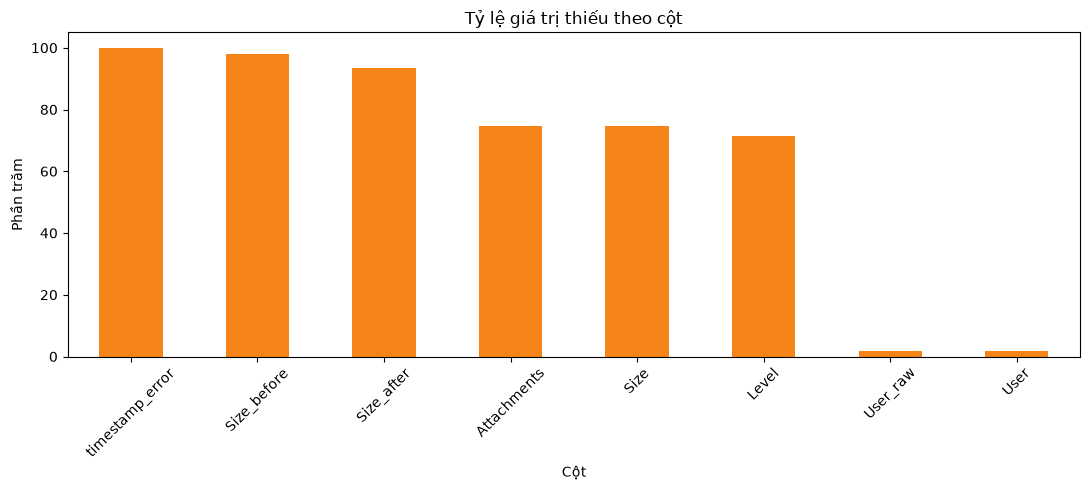

In [3]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
})
display(schema)
print(f"Dòng trùng hoàn toàn: {df.duplicated().sum():,}")
display(df.head())

missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
if not missing_pct.empty:
    fig, ax = plt.subplots(figsize=(11, 5))
    missing_pct.plot.bar(ax=ax, color="#F58518")
    ax.set(title="Tỷ lệ giá trị thiếu theo cột", ylabel="Phần trăm", xlabel="Cột")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "01_missing_values.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
    print("Không có giá trị thiếu.")

## 2. Phân bố nhãn và loại hoạt động

Tỷ lệ nhãn được xem xét theo Activity để nhận diện mất cân bằng giữa các nhóm; tỷ lệ cao trong dữ liệu này không đồng nghĩa với hiệu năng tương tự trên log mới.

,count,percent
Anomaly,,
0,30709,42.5
1,41541,57.5


,count
Activity,
http,21723
email,18203
file,12405
command,10114
session,5399
device,4406


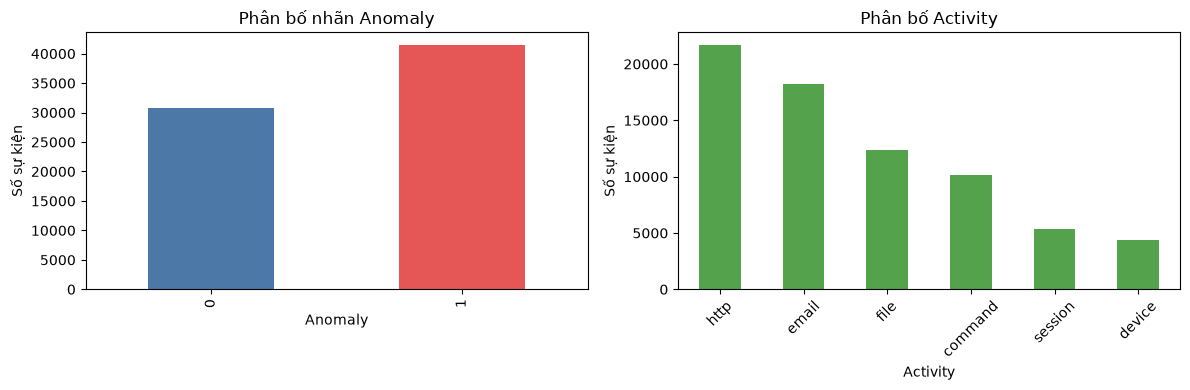

Anomaly,Anomaly=0 (%),Anomaly=1 (%)
Activity,,
command,8.54,91.46
device,40.69,59.31
email,28.51,71.49
file,50.83,49.17
http,61.52,38.48
session,59.14,40.86


In [4]:
label_counts = df["Anomaly"].value_counts(dropna=False).sort_index()
label_summary = label_counts.rename("count").to_frame()
label_summary["percent"] = (label_summary["count"] / len(df) * 100).round(2)
display(label_summary)

activity_counts = df["Activity"].value_counts(dropna=False)
display(activity_counts.rename("count").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
label_counts.plot.bar(ax=axes[0], color=["#4C78A8", "#E45756"][:len(label_counts)])
axes[0].set(title="Phân bố nhãn Anomaly", xlabel="Anomaly", ylabel="Số sự kiện")
activity_counts.plot.bar(ax=axes[1], color="#54A24B")
axes[1].set(title="Phân bố Activity", xlabel="Activity", ylabel="Số sự kiện")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(REPORT_DIR / "02_labels_and_activity.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

activity_target = pd.crosstab(df["Activity"], df["Anomaly"], normalize="index") * 100
display(activity_target.round(2).rename(columns=lambda label: f"Anomaly={label} (%)"))

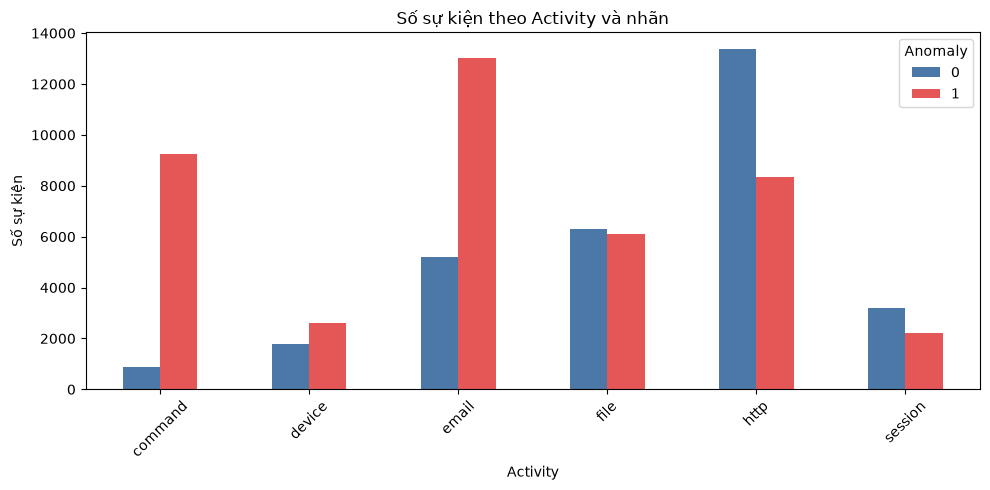

In [5]:
activity_by_label = df.groupby(["Activity", "Anomaly"], dropna=False).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5))
activity_by_label.plot.bar(ax=ax, color=["#4C78A8", "#E45756"][:len(activity_by_label.columns)])
ax.set(title="Số sự kiện theo Activity và nhãn", xlabel="Activity", ylabel="Số sự kiện")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(REPORT_DIR / "03_activity_by_label.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 3. Khám phá theo thời gian

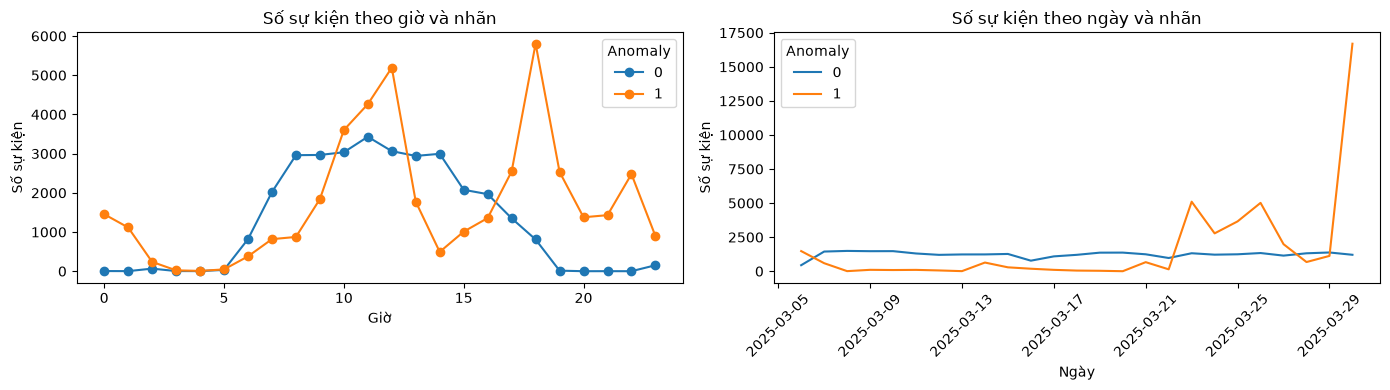

,count,anomaly_rate
Timestamp,,
0,6743,0.44
1,7549,0.504
2,9002,0.567
3,7653,0.453
4,7797,0.329
5,6657,0.234
6,26849,0.822


In [7]:
valid_time = df.loc[df["Timestamp"].notna()].copy()
valid_time["hour"] = valid_time["Timestamp"].dt.hour
valid_time["date"] = valid_time["Timestamp"].dt.date
hourly = valid_time.groupby(["hour", "Anomaly"], dropna=False).size().unstack(fill_value=0)
daily = valid_time.groupby(["date", "Anomaly"], dropna=False).size().unstack(fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hourly.plot(ax=axes[0], marker="o")
axes[0].set(title="Số sự kiện theo giờ và nhãn", xlabel="Giờ", ylabel="Số sự kiện")
daily.plot(ax=axes[1])
axes[1].set(title="Số sự kiện theo ngày và nhãn", xlabel="Ngày", ylabel="Số sự kiện")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(REPORT_DIR / "04_temporal_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

anomaly_flag = pd.to_numeric(valid_time["Anomaly"], errors="raise")
weekday = valid_time["Timestamp"].dt.dayofweek
weekday_summary = anomaly_flag.groupby(weekday).agg(["count", "mean"]).rename(columns={"mean": "anomaly_rate"}).round(3)
display(weekday_summary)

## 4. Đặc trưng phân loại và nguy cơ leakage

Các cột văn bản/raw và định danh không được đưa vào feature mặc định. Bảng dưới đây chỉ mô tả độ đa dạng của các trường; không kết luận quan hệ nhân quả.

,column,unique_values
0,Activity,6
1,Action,13
2,Decoder_name,7
3,User,17
4,Agent_name,83


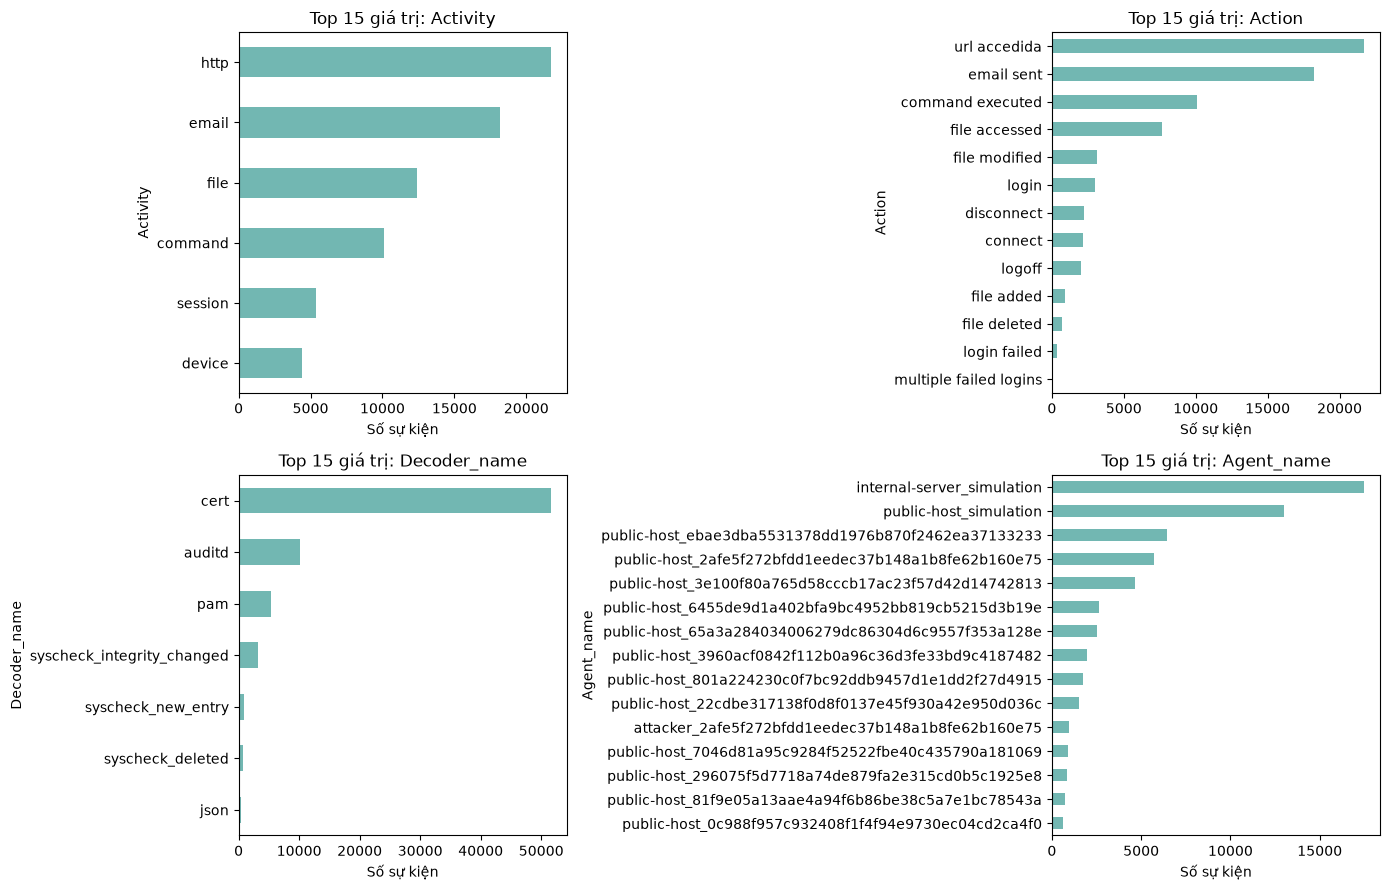

Feature ứng viên: ['hour', 'day_of_week', 'Activity', 'Action', 'Decoder_name', 'User', 'Agent_name', 'User_events_15min_past', 'Agent_name_events_15min_past']
Loại khỏi feature mặc định: ['Anomaly', 'id', 'Level', 'Description', 'Full_log', 'Content']


In [8]:
categorical_columns = ["Activity", "Action", "Decoder_name", "User", "Agent_name"]
display(pd.DataFrame({
    "column": categorical_columns,
    "unique_values": [df[column].nunique(dropna=True) for column in categorical_columns],
}))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, column in zip(axes.ravel(), ["Activity", "Action", "Decoder_name", "Agent_name"]):
    df[column].value_counts(dropna=False).head(15).sort_values().plot.barh(ax=ax, color="#72B7B2")
    ax.set(title=f"Top 15 giá trị: {column}", xlabel="Số sự kiện", ylabel=column)
fig.tight_layout()
fig.savefig(REPORT_DIR / "05_top_categories.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

candidate_features = [
    "hour", "day_of_week", "Activity", "Action", "Decoder_name",
    "User", "Agent_name", "User_events_15min_past",
    "Agent_name_events_15min_past",
]
excluded_from_default_features = [
    "Anomaly", "id", "Level", "Description", "Full_log", "Content",
]
print("Feature ứng viên:", candidate_features)
print("Loại khỏi feature mặc định:", excluded_from_default_features)

## 5. Chia dữ liệu theo thời gian và kiểm tra drift nhãn

Dùng đúng hàm chia được script huấn luyện sử dụng: 64% train, 16% validation và 20% test theo thời gian. Validation dùng chọn threshold; test là giai đoạn mới hơn.

In [9]:
from models.train_model import load_training_data, temporal_split

training_data = load_training_data()
train, validation, test = temporal_split(training_data)
split_rows = []
for name, split in [("train", train), ("validation", validation), ("test", test)]:
    split_rows.append({
        "split": name,
        "rows": len(split),
        "start": split["Timestamp"].min(),
        "end": split["Timestamp"].max(),
        "anomaly_rate": split["Anomaly"].mean(),
        "normal_count": int((split["Anomaly"] == 0).sum()),
        "anomaly_count": int((split["Anomaly"] == 1).sum()),
    })
split_summary = pd.DataFrame(split_rows)
display(split_summary)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(split_summary["split"], split_summary["anomaly_rate"], color="#E45756")
ax.set(title="Tỷ lệ Anomaly theo temporal split", xlabel="Split", ylabel="Tỷ lệ Anomaly")
ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(REPORT_DIR / "06_temporal_label_shift.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

,split,rows,start,end,anomaly_rate,normal_count,anomaly_count
0,train,46240,2025-03-06 11:46:28,2025-03-26 22:12:28.000,0.445004,25663,20577
1,validation,11560,2025-03-26 22:12:29,2025-03-30 10:19:34.000,0.625433,4330,7230
2,test,14450,2025-03-30 10:19:36,2025-03-30 19:45:22.120,0.950450,716,13734


C:\Users\Admin\AppData\Local\Temp\ipykernel_14564\4016689472.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 6. Kết quả mô hình đã huấn luyện

Metric là kết quả thực nghiệm trên đúng dataset/split hiện tại, không phải cam kết trên log mới. Anomaly score của các pipeline không mặc định đã calibration.

In [10]:
metrics_path = PROJECT_ROOT / "reports" / "ml" / "model_metrics.csv"
thresholds_path = PROJECT_ROOT / "reports" / "ml" / "model_thresholds.json"
if metrics_path.is_file():
    display(pd.read_csv(metrics_path).round(4))
else:
    print("Chưa có model_metrics.csv; chạy python -m models.train_model để tạo báo cáo.")

if thresholds_path.is_file():
    import json
    with thresholds_path.open(encoding="utf-8") as file:
        thresholds = json.load(file)
    display(pd.Series(thresholds, name="validation_threshold").to_frame())
else:
    print("Chưa có model_thresholds.json.")

,accuracy,precision,recall,f1,pr_auc,model,model_key,feature_set,validation_threshold,validation_f1,test_rows
0,0.9998,1.0000,0.9998,0.9999,1.0000,Logistic Regression,logistic_regression,"hour, day_of_week, Activity, Action, Decoder_n...",0.4125,1.0000,14450
1,1.0000,1.0000,1.0000,1.0000,1.0000,Random Forest,random_forest,"hour, day_of_week, Activity, Action, Decoder_n...",0.5400,1.0000,14450
2,0.9839,0.9921,0.9910,0.9915,0.9998,Random Forest Behavioral,random_forest_behavioral,"hour, day_of_week, Activity, Action, Decoder_n...",0.1800,0.9658,14450


,validation_threshold
logistic_regression.joblib,0.412524
random_forest.joblib,0.540000
random_forest_behavioral.joblib,0.180000


## Kết luận EDA

- Các biểu đồ được sinh từ dữ liệu bằng code trong notebook.
- `Anomaly`, `id`, `Level` và các trường raw/văn bản rủi ro cao không phải feature mặc định.
- Temporal split cho thấy tỷ lệ nhãn thay đổi giữa train, validation và test; cần diễn giải metric thận trọng và đánh giá thêm trên log mới.
- Threshold được chọn trên validation; thay đổi threshold có thể đổi cân bằng precision/recall. Score chỉ là tín hiệu ưu tiên phân loại, không phải xác suất đã calibration.